[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/PhenoMe-Ecosystem/PhenoMe/blob/main/Notebooks/tutorials/01_interactive_quickstart.ipynb)

# Tutorial 01: Interactive Phenotyping (Zero Code)

Welcome to PhenoMe! This notebook provides a completely point-and-click, zero-code introduction to AI-powered phenotyping. All Python code is folded behind interactive buttons and dropdown menus.

**Colab Quick Start:**
1. **Enable GPU (Free):** Go to **Runtime → Change runtime type → T4 GPU** (recommended for speed).
2. **Run step-by-step:** Click the **▶ (Play)** button on each cell from top to bottom (or press **Shift + Enter**), then use the interactive menus and buttons.

**Datasets:**
By default, this tutorial lets you choose between two toy datasets—*E. coli* fluorescence microscopy images across 7 antibiotic conditions ([Spahn et al., Nat Commun 2025](https://doi.org/10.1038/s41467-025-58723-4)) and **human FUCCI cell cycle images**—or load your own images in Step 2.

**Author:** Aitor González-Marfil ([@AAitorG](https://github.com/AAitorG))


In [2]:
# @title (Run this cell) Install PhenoMe
try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    %pip install -q --no-warn-conflicts git+https://github.com/PhenoMe-Ecosystem/PhenoMe.git
    print("✓ PhenoMe installed successfully! Proceed to Step 1.")
else:
    print("✓ Running in local environment. Proceed to Step 1.")


✓ Running in local environment. Proceed to Step 1.


### Adaptations to run on local machine (NEW)

------------- New ----------------   
The notebook is adapted to run smoothly on the local machine (Windows), instead of relying strictly on Google Colab.

**Project path configuration** :
Checks if the local project directory and package exist, changes the current working directory to the project root, and inserts it into sys.path so the phenome package can be successfully imported.

**DLL search path management** : 
Adds Conda/Python environment binary directories (Library/bin and DLLs) to Windows' DLL search paths (os.add_dll_directory) and maintains active handles to prevent import errors with native libraries like Pillow or PyTorch.   

**Package verification** : 
Imports critical external libraries (such as PIL) and core functions from phenome (PhenoMe, load_dinov2_model, make_dataframe_metadata_fn) to confirm that the environment is fully initialized and ready for execution.



In [3]:
# Local repository / Windows setup
from windows_setup import setup_local_phenome

REPO_ROOT = setup_local_phenome(verify_imports=True)
print("Repository root:", REPO_ROOT)
print("✓ Local environment configured.")


Repository root: C:\Users\jufki\CS_433_ML\ML_project2\ML_PhenoMe
✓ Local environment configured.


## Step 1: Initialize PhenoMe

Run the cell below to load PhenoMe and verify whether a GPU is available.


In [5]:
# MODIFIED --------------------------------------------------------

# @title (Run this cell) Initialize environment & check GPU
import importlib
import sys
import zipfile
from pathlib import Path
import numpy as np
import ipywidgets as widgets
import pandas as pd
import requests
import torch
from IPython.display import clear_output, display
from visualization_utils import display_dataset_image

try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

# Import project and dataset helpers from the companion modules
from phenome import PhenoMe, load_dinov2_model, make_dataframe_metadata_fn
import fucci_dataset_utils

if IN_COLAB:
    import plotly.io as pio
    pio.renderers.default = "colab"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if device.type == "cuda":
    print(f"✓ GPU detected: {torch.cuda.get_device_name(0)}")
else:
    print("ℹ Using CPU. In Colab, go to Runtime → Change runtime type → T4 GPU for faster processing.")

# Shared session state
pheno = None
file_df = None
metadata_df = None
model_wrapper = None
using_toy_dataset = False
active_toy_config = None
explorer = None

_SKIP_COLUMNS = {
    "file_path", "mask_path", "filename", "id", "img_path",
    "image_path", "image_crop", "image_index", "_internal_group",
}
_PREFERRED_COLUMNS = ("drug_name", "phase", "cell_cycle", "condition", "treatment", "drug", "group", "timepoint", "time")

TOY_DATASETS = {
    "ecoli": {
        "label": "Use Toy E. coli Dataset (Default)",
        "url": (
            "https://upvehueus-my.sharepoint.com/:u:/g/personal/aitor_gonzalezm_ehu_eus/"
            "IQCBYEL7E_-NTZZeIsBhwwG8AbI9BucCBAgaPacYqXjDsA4?download=1"
        ),
        "zip_name": "ecoli_dataset.zip",
        "output_dir": "./toy_dataset_ecoli",
        "images_folder": "Ecoli_images",
        "masks_folder": "Ecoli_masks",
        "extensions": [".tif"],
        "pad_size": 168,
        "channel_mode": "split",
    },

    # --- MODIFIED: Local FUCCI toy datasets -----------------------------
    "fucci": {
        "label": "Use Local FUCCI Dataset (fucci_datasets)",
        "source_type": "local_fucci",
        "default_subset": "test",
        "images_folder": "FUCCI_images",
        "masks_folder": "FUCCI_masks",
        "extensions": [".png", ".tif", ".tiff"],
        "pad_size": None,
        "channel_mode": "combined",
    },
    # --------------------------------------------------------------------
}

def has_embeddings():
    return pheno is not None and pheno.results.embeddings is not None and len(pheno.results.embeddings) > 0

def get_condition_columns():
    """Return available experimental condition and grouping columns."""
    candidate_cols = []
    if file_df is not None:
        candidate_cols = [c for c in file_df.columns if c not in _SKIP_COLUMNS]
    elif pheno is not None:
        candidate_cols = [k for k in pheno.get_available_metadata_keys() if k not in _SKIP_COLUMNS]

    total = len(file_df) if file_df is not None else (pheno.results.n_images if pheno is not None else 0)
    valid_cols = []
    for col in candidate_cols:
        if file_df is not None and col in file_df.columns:
            n_unique = file_df[col].nunique(dropna=True)
        elif pheno is not None and pheno.results.metadata:
            vals = [m.get(col) for m in pheno.results.metadata if isinstance(m, dict) and col in m]
            n_unique = len(set(vals))
        else:
            n_unique = 0
        # Exclude columns where almost every row is unique (like image identifiers/hashes)
        if total > 10 and n_unique >= total * 0.95:
            continue
        if n_unique >= 1:
            valid_cols.append(col)
    return valid_cols

def preferred_column(columns):
    for name in _PREFERRED_COLUMNS:
        if name in columns:
            return name
    return columns[0] if columns else None

def get_prototype_options():
    cols = get_condition_columns()
    if not cols:
        return [("No condition columns found", "")]
    options = []
    for col in cols:
        n_unique = file_df[col].nunique(dropna=True) if (file_df is not None and col in file_df.columns) else None
        label = f"{col} ({n_unique} conditions)" if n_unique else col
        options.append((label, col))
    return options

def get_outlier_options():
    cols = get_condition_columns()
    options = [("All images (dataset-wide)", "all")]
    for col in cols:
        n_unique = file_df[col].nunique(dropna=True) if (file_df is not None and col in file_df.columns) else None
        label = f"{col} ({n_unique} groups)" if n_unique else col
        options.append((label, col))
    return options

def refresh_column_menus():
    """Update condition dropdowns across Step 5 and Step 6 if they are already created."""
    cond_dropdown = globals().get("condition_name")
    if cond_dropdown is not None:
        opts = get_prototype_options()
        pref = preferred_column(get_condition_columns())
        cond_dropdown.options = opts
        valid_values = [v for _, v in opts if v]
        if pref in valid_values:
            cond_dropdown.value = pref
        elif valid_values:
            cond_dropdown.value = valid_values[0]

    outlier_dropdown = globals().get("groupby_condition")
    if outlier_dropdown is not None:
        opts = get_outlier_options()
        current = outlier_dropdown.value
        outlier_dropdown.options = opts
        valid_values = [v for _, v in opts]
        outlier_dropdown.value = current if current in valid_values else "all"

def processing_batch_size():
    name = getattr(model_wrapper, "model_name", "") or ""
    gpu = device.type == "cuda"
    if "vitg" in name:
        return 4 if gpu else 1
    if "vitl" in name:
        return 8 if gpu else 2
    return 32 if gpu else 8


def setup_toy_dataset(dataset_key, fucci_subset=None, max_tracks=25, frame_stride=2):
    """
    Resolve the root directory and config for a built-in or local FUCCI dataset.
    For 'fucci', prepares and loads the selected subset directly from disk (no URL/zip).
    """
    cfg = TOY_DATASETS[dataset_key]

    # 1. Local FUCCI branch: prepare/load directly from fucci_datasets/<fucci_subset>
    if cfg.get("source_type") == "local_fucci":
        subset = fucci_subset or cfg.get("default_subset", "test")
        fucci_utils = importlib.reload(fucci_dataset_utils)
        raw_root, out_root = fucci_utils.resolve_fucci_roots()
        _, meta_path = fucci_utils.prepare_fucci_subset(
            subset,
            raw_root=raw_root,
            out_root=out_root,
            max_tracks=max_tracks,  # adjust or set to None for all tracks
            frame_stride=frame_stride, # adjust (1 = every frame, 5 = every 5th frame)
        )
        generated_metadata = pd.read_csv(meta_path)
        expected_label_columns = {"fucci_label_0", "fucci_label_1"}
        missing_label_columns = expected_label_columns.difference(generated_metadata.columns)
        if missing_label_columns:
            raise RuntimeError(
                f"FUCCI helper {fucci_utils.__file__} generated metadata without "
                f"label columns: {sorted(missing_label_columns)}"
            )
        root_path = Path(meta_path).parent  # .../fucci_toy_datasets/<subset>
        print(f"Using local FUCCI subset '{subset}' at {root_path}")
        return str(root_path), cfg

    # 2. Remote URL / zip branch (used for E. coli toy dataset)
    output_path = Path(cfg["output_dir"])
    output_path.mkdir(exist_ok=True, parents=True)
    images_folder = cfg["images_folder"]

    existing = list(output_path.glob(f"**/{images_folder}"))
    if existing:
        print(f"Found existing dataset at {existing[0].parent}")
        return str(existing[0].parent), cfg

    url_or_path = cfg["url"]
    zip_name = cfg["zip_name"]
    zip_path = output_path / zip_name
    if not zip_path.is_file():
        print(f"Downloading {dataset_key} dataset...")
        r = requests.get(url_or_path, stream=True)
        r.raise_for_status()
        with open(zip_path, "wb") as f:
            for chunk in r.iter_content(chunk_size=1024 * 1024):
                if chunk:
                    f.write(chunk)

    with zipfile.ZipFile(zip_path, "r") as zf:
        zf.extractall(output_path)

    extracted = list(output_path.glob(f"**/{images_folder}"))
    if extracted:
        return str(extracted[0].parent), cfg

    raise RuntimeError(f"Failed to setup dataset {dataset_key}")


print("✓ Environment initialized. Proceed to Step 1.1.")


ℹ Using CPU. In Colab, go to Runtime → Change runtime type → T4 GPU for faster processing.
✓ Environment initialized. Proceed to Step 1.1.


## Step 1.1: Choose Your Vision Model

PhenoMe uses foundation vision models (DINOv2) to extract phenotypic representations from cell images.

- **Small (ViT-S/14):** Fast and lightweight. **Recommended for Colab.**
- **Base (ViT-B/14):** Balanced middle ground between speed and sensitivity.
- **Large / Giant:** Finer detail, but heavier and may exhaust free Colab GPU memory.

Select a model size and click **Load Model**.


In [6]:
# @title (Run this cell) Select and load AI model
model_options = {
    "Small (ViT-S/14)": ("dinov2_vits14_reg", "<b>Small (ViT-S/14)</b>: Fast, light, and recommended for Colab."),
    "Base (ViT-B/14)": ("dinov2_vitb14_reg", "<b>Base (ViT-B/14)</b>: Balanced speed and sensitivity."),
    "Large (ViT-L/14)": ("dinov2_vitl14_reg", "<b>Large (ViT-L/14)</b>: Finer details, slower (requires GPU)."),
    "Giant (ViT-g/14)": ("dinov2_vitg14_reg", "<b>Giant (ViT-g/14)</b>: Maximum detail (heavy on GPU memory)."),
}

model_dropdown = widgets.Dropdown(
    options=list(model_options.keys()),
    value="Small (ViT-S/14)",
    description="Model Size:",
    style={"description_width": "initial"},
)

model_description = widgets.HTML(
    value=model_options["Small (ViT-S/14)"][1],
    layout=widgets.Layout(margin="0 0 10px 0")
)

def on_model_change(change):
    model_description.value = model_options[change["new"]][1]

model_dropdown.observe(on_model_change, names="value")

load_model_button = widgets.Button(description="Load Model", button_style="primary")
model_output = widgets.Output()

def on_load_model_clicked(b):
    global model_wrapper, pheno, file_df
    with model_output:
        clear_output(wait=True)
        try:
            model_name = model_options[model_dropdown.value][0]
            print(f"Loading {model_dropdown.value} ({model_name})...")
            model_wrapper = load_dinov2_model(model_name=model_name, device=device)
            pheno = PhenoMe(device=device, seed=42)
            file_df = None
            print(f"✓ {model_dropdown.value} loaded successfully! Proceed to Step 2.")
        except Exception as e:
            print(f"Error loading model: {e}")

load_model_button.on_click(on_load_model_clicked)
display(widgets.VBox([model_dropdown, model_description, load_model_button, model_output]))


## Step 2: Load Your Images

Choose whether to explore one of the built-in/local datasets or your own custom folder, then click **Load Dataset**.

- **Toy *E. coli* Dataset (Default):** 1,530 *E. coli* cells across 7 antibiotic treatments with segmentation masks and metadata (`drug_name`, `time`).
- **Local FUCCI Dataset (`fucci_datasets`):** Choose between `train`, `test`, `test_drugged`, or `combined` (the three subsets merged with condition labels) directly from your local `fucci_datasets/` directory. The toy-dataset exporter segments the center-nearest nucleus, saves a crop with a 10% margin around its mask plus a matching mask file; frames without a detected nucleus are skipped.
- **Custom Images:** Provide the path to any folder of images (e.g., `./fucci_toy_datasets/test/FUCCI_images`). Masks and metadata CSV are optional.


In [7]:
# MODIFIED ------------------------------------------------

# @title (Run this cell) Choose and load image dataset
dataset_mode = widgets.RadioButtons(
    options=[
        (TOY_DATASETS["ecoli"]["label"], "ecoli"),
        (TOY_DATASETS["fucci"]["label"], "fucci"),
        ("Use Custom Images", "custom"),
    ],
    value="fucci",
    description="Mode:",
    style={"description_width": "initial"},
)

# Dropdown to select which local FUCCI subset to load when Mode == "fucci"
fucci_subset_dropdown = widgets.Dropdown(
    options=[
        ("train", "train"),
        ("test (untreated / control)", "test"),
        ("test_drugged (drug-treated)", "test_drugged"),
        ("combined (train + test + test_drugged)", "combined"),
    ],
    value="train",
    description="FUCCI Dataset:",
    style={"description_width": "initial"},
    layout=widgets.Layout(width="50%"),
)

# NEW ----------------------------------------------------
fucci_max_tracks_input = widgets.BoundedIntText(
    value=25,
    min=1,
    max=10000,
    step=1,
    description="Max Tracks (Cells):",
    style={"description_width": "initial"},
    layout=widgets.Layout(width="35%"),
)

fucci_frame_stride_input = widgets.BoundedIntText(
    value=2,
    min=1,
    max=100,
    step=1,
    description="Frame Stride:",
    style={"description_width": "initial"},
    layout=widgets.Layout(width="35%"),
)
# ------------------------------------------------------


data_path_input = widgets.Text(
    value="",
    description="Images Directory:",
    placeholder="/content/my_images",
    style={"description_width": "initial"},
    layout=widgets.Layout(width="80%"),
)

csv_path_input = widgets.Text(
    value="",
    description="Metadata CSV (optional):",
    placeholder="(Optional) /content/metadata.csv",
    style={"description_width": "initial"},
    layout=widgets.Layout(width="80%"),
)

mask_path_input = widgets.Text(
    value="",
    description="Masks Directory (optional):",
    placeholder="(Optional) /content/masks",
    style={"description_width": "initial"},
    layout=widgets.Layout(width="80%"),
)

load_button = widgets.Button(description="Load Dataset", button_style="primary")
mount_drive_button = widgets.Button(description="Mount Google Drive")
dataset_output = widgets.Output()

def on_mount_drive_clicked(_):
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        if not data_path_input.value.strip():
            data_path_input.value = "/content/drive/MyDrive/"
        with dataset_output:
            clear_output(wait=True)
            print("✓ Google Drive mounted. Set your folder path under /content/drive/MyDrive/.")
    except Exception as exc:
        with dataset_output:
            clear_output(wait=True)
            print(f"Could not mount Google Drive: {exc}")

# Store the currently loaded dataset selection
active_dataset_mode = None
active_dataset_subset = None

def on_load_clicked(b):
    global file_df, metadata_df, using_toy_dataset, active_toy_config
    if pheno is None or model_wrapper is None:
        with dataset_output:
            clear_output(wait=True)
            print("⚠️ Please load an AI model first in Step 1.1.")
        return

    with dataset_output:
        clear_output(wait=True)
        try:
            mode = dataset_mode.value
            global active_dataset_mode, active_dataset_subset
            active_dataset_mode = mode
            active_dataset_subset = (
                fucci_subset_dropdown.value if mode == "fucci" else None
            )
            if mode in TOY_DATASETS:
                # Pass the selected FUCCI subset when mode == 'fucci'
                selected_subset = fucci_subset_dropdown.value if mode == "fucci" else None
                selected_max_tracks = fucci_max_tracks_input.value if mode == "fucci" else None
                selected_frame_stride = fucci_frame_stride_input.value if mode == "fucci" else None
                dataset_root, cfg = setup_toy_dataset(
                    mode, 
                    fucci_subset=selected_subset,
                    max_tracks=selected_max_tracks,
                    frame_stride=selected_frame_stride
                )
                if not dataset_root:
                    return
                root_path = Path(dataset_root)
                images_dir = root_path / cfg["images_folder"]
                masks_dir = root_path / cfg["masks_folder"]
                metadata_csv = root_path / "metadata.csv"

                metadata_fn = None
                if metadata_csv.is_file():
                    metadata_df = pd.read_csv(metadata_csv)
                    metadata_fn = make_dataframe_metadata_fn(metadata_df)

                print(f"Scanning images in {images_dir}...")
                file_df = pheno.find_files(
                    str(images_dir),
                    extensions=cfg["extensions"],
                    metadata_fn=metadata_fn,
                    mask_dir=str(masks_dir) if masks_dir.is_dir() else None,
                )
                using_toy_dataset = True
                active_toy_config = cfg

                cm_dropdown = globals().get("channel_mode_dropdown")
                if cm_dropdown is not None and cfg.get("channel_mode"):
                    cm_dropdown.value = cfg["channel_mode"]
            else:
                images_dir_val = data_path_input.value.strip()
                if not images_dir_val:
                    print("⚠️ Please enter the directory path containing your images.")
                    return
                if not Path(images_dir_val).is_dir():
                    print(f"⚠️ Directory not found: {images_dir_val}. Please verify the path.")
                    return

                csv_val = csv_path_input.value.strip()
                metadata_fn = None
                if csv_val:
                    if not Path(csv_val).is_file():
                        print(f"⚠️ Metadata CSV not found: {csv_val}.")
                        return
                    metadata_df = pd.read_csv(csv_val)
                    metadata_fn = make_dataframe_metadata_fn(metadata_df)

                mask_dir_val = mask_path_input.value.strip() or None
                if mask_dir_val and not Path(mask_dir_val).is_dir():
                    print(f"⚠️ Masks directory not found: {mask_dir_val}. Proceeding without masks.")
                    mask_dir_val = None

                print(f"Scanning images in {images_dir_val}...")
                file_df = pheno.find_files(
                    images_dir_val, metadata_fn=metadata_fn, mask_dir=mask_dir_val
                )
                using_toy_dataset = False
                active_toy_config = None

            if file_df is None or len(file_df) == 0:
                file_df = None
                print("⚠️ No images found. Check the directory path and filenames.")
                return

            conditions = get_condition_columns()
            display(file_df.head(3))
            print(f"✓ Found {len(file_df)} images with condition column(s): {conditions}")
            refresh_column_menus()
            print("✓ Dataset ready! Proceed to Step 3.")
        except Exception as e:
            file_df = None
            print(f"Error loading dataset: {e}")

load_button.on_click(on_load_clicked)
mount_drive_button.on_click(on_mount_drive_clicked)

def update_ui(_change):
    global active_dataset_mode, active_dataset_subset
    mode = dataset_mode.value
    # NEW ----------------------------------------------------
    active_dataset_mode = mode
    active_dataset_subset = (
        fucci_subset_dropdown.value if mode == "fucci" else None
    )
    #--------------------------------------------------------
    custom = mode == "custom"
    fucci = mode == "fucci"
    for widget in (fucci_subset_dropdown, fucci_max_tracks_input, fucci_frame_stride_input):
        widget.layout.display = "flex" if fucci else "none"
    for widget in (csv_path_input, data_path_input, mask_path_input):
        widget.layout.display = "flex" if custom else "none"
    mount_drive_button.layout.display = "flex" if custom and IN_COLAB else "none"


dataset_mode.observe(update_ui, names="value")
update_ui(None)

display(widgets.VBox([
    dataset_mode,
    fucci_subset_dropdown,
    fucci_max_tracks_input,
    fucci_frame_stride_input,
    data_path_input,
    csv_path_input,
    mask_path_input,
    mount_drive_button,
    load_button,
    dataset_output,
]))


In [38]:
print("Selected mode:", dataset_mode.value)
print("Loaded dataset:", active_dataset_mode)
print("Number of images:", len(file_df) if file_df is not None else 0)
print("Toy dataset:", using_toy_dataset)

Selected mode: fucci
Loaded dataset: fucci
Number of images: 30
Toy dataset: True


### 2.1. Visual inspection of the dataset

Before proceeding with preprocessing and analysis, we visualize an example image from the selected dataset.

This step allows us to inspect image quality, dimensions, channels, and fluorescence or staining patterns. The visualization function adapts to the image format and can be reused across different datasets.

Displaying FUCCI dataset — subset: test (test_t0000_f0000.tiff)


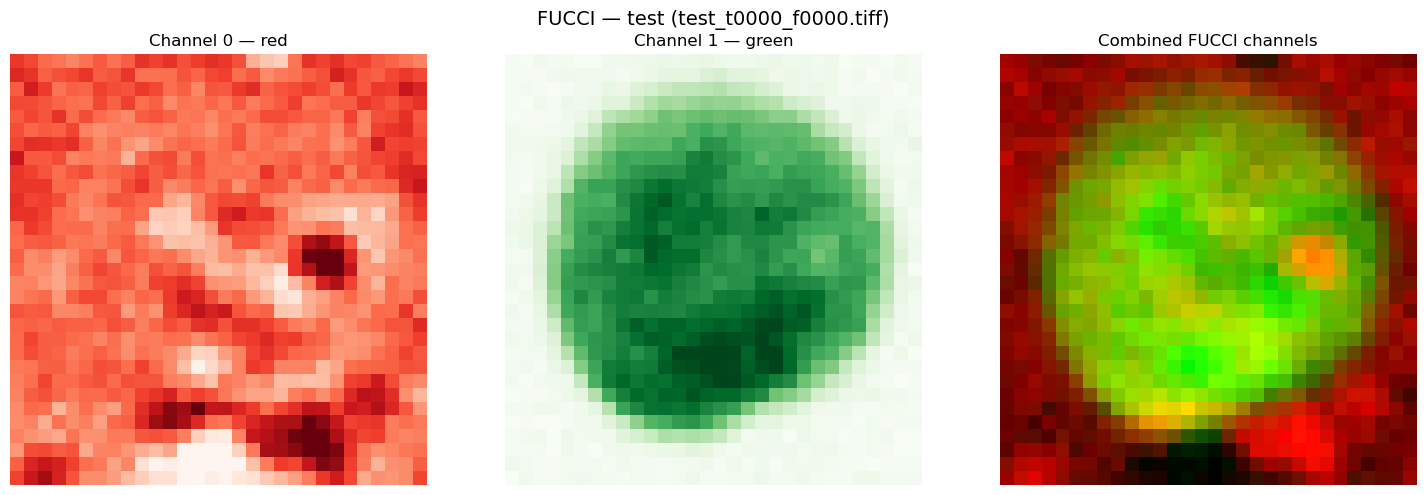

In [39]:
from pathlib import Path
import numpy as np
import tifffile
from PIL import Image

if active_dataset_mode is None or file_df is None or len(file_df) == 0:
    print("Please load a dataset first.")
else:
    # Récupère le chemin du premier fichier chargé dans file_df
    path_col = next(
        (c for c in ("file_path", "image_path", "img_path", "filename") if c in file_df.columns),
        None,
    )
    if path_col is None:
        raise KeyError(f"Aucune colonne de chemin trouvée dans file_df : {list(file_df.columns)}")

    img_path = Path(file_df.iloc[0][path_col])
    suffix = img_path.suffix.lower()

    if suffix == ".npy":
        sample_img = np.load(img_path, allow_pickle=False)
        # Si c'est une piste temporelle (T, C, H, W), on prend la frame 0
        if sample_img.ndim == 4:
            sample_img = sample_img[0]
    elif suffix in {".tif", ".tiff"}:
        sample_img = tifffile.imread(img_path)
    else:
        sample_img = np.asarray(Image.open(img_path))

    if active_dataset_mode == "fucci":
        print(f"Displaying FUCCI dataset — subset: {active_dataset_subset} ({img_path.name})")
        display_dataset_image(
            sample_img,
            dataset_name="fucci",
            title=f"FUCCI — {active_dataset_subset} ({img_path.name})",
        )
    elif active_dataset_mode == "ecoli":
        print(f"Displaying E. coli dataset ({img_path.name})")
        display_dataset_image(
            sample_img,
            dataset_name="ecoli",
            title=f"E. coli — {img_path.name}",
        )
    else:
        print(f"Displaying custom dataset ({img_path.name})")
        display_dataset_image(
            sample_img,
            title=f"Custom — {img_path.name}",
        )



### 2.2. Conversion from .npy to .tiff for visualization

Save the numpy files as tiff to enable visualization in FIJI.

In [40]:
import ipywidgets as widgets

# Active dataset/split state variable (e.g., "train", "test_drugged", "ecoli", etc.)
selected_split = globals().get("selected_split", "train")

split_widget = widgets.Dropdown(
    options=["train", "test", "test_drugged"],
    value=selected_split if selected_split in ["train", "test", "test_drugged"] else "train",
    description="Dataset:",
)


def _sync_selected_split(change=None):
    global selected_split
    selected_split = split_widget.value if change is None else change["new"]


_sync_selected_split()
split_widget.observe(_sync_selected_split, names="value")
display(split_widget)

Dropdown(description='Dataset:', index=2, options=('train', 'test', 'test_drugged'), value='test_drugged')

In [41]:
from pathlib import Path
import numpy as np
import tifffile as tiff

# Sync from the dropdown widget if it exists
if "split_widget" in globals() and getattr(split_widget, "value", None):
    selected_split = split_widget.value

raw_root, _ = fucci_dataset_utils.resolve_fucci_roots()
dataset_dir = Path(raw_root) / selected_split / "images"
output_dir = Path(raw_root) / selected_split / f"{selected_split}_tiff"

existing_tiffs = list(output_dir.rglob("*.tif*")) if output_dir.exists() else []
if output_dir.exists() and existing_tiffs:
    print(f"Skipping conversion: '{output_dir}' already exists ({len(existing_tiffs)} TIFF files).")
else:
    output_dir.mkdir(parents=True, exist_ok=True)
    npy_files = sorted(dataset_dir.rglob("*.npy"))

    for file in npy_files:
        img = np.load(file)
        output_file = output_dir / file.relative_to(dataset_dir).with_suffix(".tiff")
        output_file.parent.mkdir(parents=True, exist_ok=True)
        tiff.imwrite(output_file, img)

    print(f"Converted {len(npy_files)} files to {output_dir}")

Skipping conversion: 'C:\Users\jufki\CS_433_ML\ML_project2\ML_PhenoMe\fucci_datasets\test\test_tiff' already exists (120 TIFF files).


### 2.3 Inspect the selected cell before normalization

FUCCI toy-dataset frames are segmented and cropped with a 10% margin around the mask when the toy dataset is prepared. This cell displays an exported crop and its matching saved mask.

In [42]:
from pathlib import Path
from skimage import io
import plotly.express as px

if file_df is None or len(file_df) == 0:
    print("Load a dataset in Step 2 to inspect FUCCI images.")
elif globals().get("active_dataset_mode") != "fucci":
    print(
        f"Skipping FUCCI inspection: current mode is '{globals().get('active_dataset_mode')}' "
        "(select 'fucci' in Step 2 to run this cell)."
    )
else:
    fucci_df = file_df[
        file_df["file_path"].astype(str).str.lower().str.endswith((".tif", ".tiff"))
    ]

    if fucci_df.empty:
        print("No FUCCI (.tif / .tiff) images found in file_df.")
    else:
        sample = fucci_df.iloc[0]
        img = io.imread(sample["file_path"])

        # Select a 2D plane depending on channel/stack layout
        if img.ndim == 3:
            if img.shape[0] <= 4 and img.shape[0] < img.shape[-1]:
                img_view = img[1] if img.shape[0] > 1 else img[0]
            elif img.shape[-1] <= 4:
                img_view = img[..., 1] if img.shape[-1] > 1 else img[..., 0]
            else:
                img_view = img[0]
        elif img.ndim == 2:
            img_view = img
        else:
            raise ValueError(f"Unsupported image shape for 2D inspection: {img.shape}")

        fig = px.imshow(
            img_view,
            color_continuous_scale="gray",
            title=f"FUCCI image: {Path(sample['file_path']).name}",
        )

        # Optional: overlay mask contour only if a valid matching mask exists
        mask_path = sample["mask_path"] if "mask_path" in fucci_df.columns else None
        if mask_path and str(mask_path).strip().lower() not in {"", "nan", "none"}:
            mask_file = Path(str(mask_path))
            if mask_file.is_file():
                mask = io.imread(mask_file).astype(bool)
                if mask.ndim > 2:
                    mask = mask[0]
                if mask.shape == img_view.shape:
                    fig.add_contour(
                        z=mask.astype(int),
                        showscale=False,
                        contours=dict(start=0.5, end=0.5, size=1, coloring="lines"),
                        line=dict(color="red", width=2),
                    )
                else:
                    print(
                        f"Note: skipping mask contour due to shape mismatch "
                        f"({img_view.shape} vs {mask.shape})."
                    )

        fig.show()

## Step 3: Process Images with AI

The AI model examines each cell image and converts it into a high-dimensional numerical profile called an **embedding**.

- **split (Recommended for fluorescence):** Analyzes each channel independently, preserving individual stain signals.
- **combined (RGB / brightfield):** Merges channels as a normal color photograph.

Select the channel mode and click **Process Images**.


In [ ]:
# @title (Run this cell) Extract AI embeddings
channel_mode_options = {
    "split": "<b>split</b>: Processes each channel independently. Recommended for multi-channel fluorescence.",
    "combined": "<b>combined</b>: Combines all channels into RGB. Best for standard color photographs.",
}

default_channel_mode = (
    active_toy_config.get("channel_mode", "split")
    if (using_toy_dataset and active_toy_config)
    else "split"
)

channel_mode_dropdown = widgets.Dropdown(
    options=list(channel_mode_options.keys()),
    value=default_channel_mode,
    description="Channel Mode:",
    style={"description_width": "initial"},
)

channel_mode_description = widgets.HTML(
    value=channel_mode_options[default_channel_mode],
    layout=widgets.Layout(margin="0 0 10px 0"),
)

def on_channel_mode_change(change):
    channel_mode_description.value = channel_mode_options[change["new"]]

channel_mode_dropdown.observe(on_channel_mode_change, names="value")

process_button = widgets.Button(description="Process Images", button_style="success")
process_output = widgets.Output()

def on_process_clicked(b):
    if file_df is None or pheno is None or model_wrapper is None:
        with process_output:
            clear_output(wait=True)
            print("⚠️ Please load a model (Step 1.1) and dataset (Step 2) first.")
        return

    with process_output:
        clear_output(wait=True)
        channel_mode = channel_mode_dropdown.value
        batch_size = processing_batch_size()
        pad_size = active_toy_config.get("pad_size") if (using_toy_dataset and active_toy_config) else None
        workers = 2 if (IN_COLAB and device.type == "cuda") else 0
        print(f"Extracting embeddings (channel mode: {channel_mode}, batch size: {batch_size})...")
        try:
            pheno.process_images(
                model_wrapper,
                num_workers=workers,
                batch_size=batch_size,
                channel_mode=channel_mode,
                resize_size=224,
                pad_size=pad_size,
            )
            refresh_column_menus()
            print(f"✓ Embeddings computed successfully for {len(file_df)} images!")
            print("✓ You can now open the Interactive Explorer (Step 4) or measure physical traits (Step 3.1).")
        except Exception as exc:
            print(f"Error processing images: {exc}")

process_button.on_click(on_process_clicked)
display(widgets.VBox([channel_mode_dropdown, channel_mode_description, process_button, process_output]))


## Step 3.1: Measure Physical Traits (Optional)

AI embeddings capture subtle phenotypic nuances, while classical properties (size, shape, brightness) provide easily interpretable physical traits.

- **Basic (Recommended):** Essential shape (area, perimeter, circularity, eccentricity) and intensity statistics.
- **Standard:** Shape, intensity stats, and concentric radial intensity profiles.
- **Intensity:** Intensity statistics only (works without segmentation masks).
- **Complete:** Advanced texture (GLCM), image quality metrics, and full shape descriptors.

Select a preset and click **Compute Properties**.


In [44]:
# @title (Run this cell) Measure physical traits
preset_info = {
    "basic": ("Basic", "<b>Basic</b>: Essential shape (area, perimeter, eccentricity) and intensity stats."),
    "standard": ("Standard", "<b>Standard</b>: Shape, intensity stats, and concentric ring features."),
    "intensity": ("Intensity", "<b>Intensity</b>: Image brightness stats only (works without masks)."),
    "complete": ("Complete", "<b>Complete</b>: Advanced texture, quality metrics, and full shape descriptors."),
}

preset_dropdown = widgets.Dropdown(
    options=[(label, name) for name, (label, _) in preset_info.items()],
    value="basic",
    description="Property Preset:",
    style={"description_width": "initial"},
)

preset_description = widgets.HTML(
    value=preset_info["basic"][1],
    layout=widgets.Layout(margin="0 0 10px 0"),
)

def on_preset_change(change):
    preset_description.value = preset_info[change["new"]][1]

preset_dropdown.observe(on_preset_change, names="value")

compute_button = widgets.Button(description="Compute Properties", button_style="success")
compute_output = widgets.Output()

def on_compute_clicked(b):
    if not has_embeddings():
        with compute_output:
            clear_output(wait=True)
            print("⚠️ Please process images first in Step 3.")
        return

    with compute_output:
        clear_output(wait=True)
        try:
            preset = preset_dropdown.value
            print(f"Computing properties ({preset_info[preset][0]} preset)...")
            results_df = pheno.compute_properties(property_preset=preset)
            refresh_column_menus()
            display(results_df.head(3))
            print(f"✓ Computed physical properties for {len(results_df)} images!")
        except Exception as e:
            print(f"Error computing properties: {e}")

compute_button.on_click(on_compute_clicked)
display(widgets.VBox([preset_dropdown, preset_description, compute_button, compute_output]))


## Step 4: Interactive Latent Space Explorer

Explore the biological landscape of your cells in 2D or 3D. Points close together correspond to cells with similar morphology.

- **Switch views:** Toggle between **UMAP**, **t-SNE**, and **PCA**. (UMAP works best for fucci)
- **Color points:** Color by treatment condition (`drug_name`) or measured physical properties.
- **Inspect cells:** Click on any point in the scatter plot to inspect the corresponding cell image.

In Google Colab this opens a simpler explorer (embedding method, appearance, and click-to-image). In Jupyter it opens the full explorer.

Run the cell below to open the dashboard and click on **Compute** to load the plot.

**Note:** If images in the next steps do not show, close this explorer and run that step again. Click this cell, open its **⋮** menu (side of the cell), and choose **Clear output**.


In [45]:
# @title (Run this cell) Launch interactive latent space explorer
if not has_embeddings():
    print("⚠️ Please process images in Step 3 before launching the explorer.")
else:
    if IN_COLAB:
        explorer = pheno.create_colab_interactive_explorer()
    else:
        explorer = pheno.create_interactive_explorer()


### Export of `pheno.results` to `analysis_exports` folder

In [46]:
import json
from pathlib import Path
import pandas as pd

# Build a descriptive run_name so different situations don't overwrite each other
max_tracks_val = globals().get("max_tracks", "all")
stride_val = globals().get("frame_stride", 1)
run_name = f"{selected_split}_tracks{max_tracks_val}_stride{stride_val}"

export_dir = Path("analysis_exports") / run_name
export_dir.mkdir(parents=True, exist_ok=True)

props_df = pd.DataFrame(pheno.results.properties)
meta_df = pd.DataFrame(pheno.results.metadata)

# Record run settings in metadata so batch_phase_analysis can group/filter by them
meta_df["selected_split"] = selected_split
meta_df["run_name"] = run_name

props_df.to_csv(export_dir / "properties.csv", index=False)
meta_df.to_csv(export_dir / "metadata.csv", index=False)

with open(export_dir / "img_path.json", "w", encoding="utf-8") as f:
    json.dump(list(pheno.results.img_path), f)

print(f"Exported {len(props_df)} cells to '{export_dir}'")

Exported 30 cells to 'analysis_exports\test_tracksall_stride1'


## Step 5: Representative Prototype Images

**Note:** If the images below do not appear, close the Step 4 explorer (click that cell, **⋮** → **Clear output**) and run this step again.

What does a "typical" cell look like for each treatment or experimental condition?

PhenoMe calculates the center (centroid) of each group in embedding space and retrieves the real images closest to that center. These **prototypes** represent the hallmark visual phenotype of each condition.

- **Condition menu:** Choose which experimental condition to group by (e.g. `drug_name` to view hallmark cells for each antibiotic treatment).
- **Prototypes per group:** Number of representative cell images to display for each condition.

Select your condition and click **Find Prototypes**.


In [14]:
# @title (Run this cell) Find prototype images per condition
proto_opts = get_prototype_options()
proto_default = preferred_column(get_condition_columns())
valid_proto_vals = [v for _, v in proto_opts if v]

condition_name = widgets.Dropdown(
    options=proto_opts,
    value=proto_default if proto_default in valid_proto_vals else (valid_proto_vals[0] if valid_proto_vals else None),
    description="Condition:",
    style={"description_width": "initial"},
)

prototypes_number = widgets.BoundedIntText(
    value=3,
    min=1,
    max=12,
    description="Prototypes per group:",
    style={"description_width": "initial"},
)

prototype_button = widgets.Button(description="Find Prototypes", button_style="primary")
prototype_output = widgets.Output()

def on_prototypes_clicked(_):
    with prototype_output:
        clear_output(wait=True)
        if not has_embeddings():
            print("⚠️ Please process images in Step 3 first.")
            return
        col = condition_name.value
        if not col:
            print("⚠️ Please select an experimental condition column from the menu.")
            return
        cluster_col = None if col == "all" else col
        target_name = "the entire dataset" if cluster_col is None else f"each condition in {cluster_col}"
        print(f"Finding {prototypes_number.value} representative prototype(s) for {target_name}...")
        try:
            prototypes = pheno.find_prototypes(
                cluster_col=cluster_col,
                n_prototypes=prototypes_number.value,
                plot=True,
            )
            if prototypes is not None and not prototypes.empty:
                display(prototypes)
            else:
                print("No prototypes could be computed.")
        except Exception as exc:
            print(f"Could not find prototypes: {exc}")

prototype_button.on_click(on_prototypes_clicked)
display(widgets.VBox([condition_name, prototypes_number, prototype_button, prototype_output]))


## Step 6: Detect Outliers and Rare Phenotypes

**Note:** If the images below do not appear, close the Step 4 explorer (click that cell, **⋮** → **Clear output**) and run this step again.

Outliers are cells whose embeddings deviate substantially from their group center (> 3 standard deviations).

**Why detect outliers?**
1. **Quality Control:** Spot segmentation errors, debris, or blurred images.
2. **Rare Phenotypes:** Discover unusual or transient cellular states (such as dividing cells).

**Grouping options in the menu below:**
- **All images (dataset-wide):** Compares every cell to the center of the entire dataset. Ideal for spotting overall imaging artifacts or extreme anomalies.
- **By condition (e.g. `drug_name`):** Compares each cell to its *own treatment group center*. Ideal for finding unusual cells *within* a specific condition without confusing treatment effects with outliers.

Select how to group your cells and click **Find Outliers**.


In [15]:
# @title (Run this cell) Detect outlier and rare phenotype cells
outlier_opts = get_outlier_options()

groupby_condition = widgets.Dropdown(
    options=outlier_opts,
    value="all",
    description="Group by:",
    style={"description_width": "initial"},
)

outlier_button = widgets.Button(description="Find Outliers", button_style="primary")
outlier_output = widgets.Output()

def on_outliers_clicked(_):
    with outlier_output:
        clear_output(wait=True)
        if not has_embeddings():
            print("⚠️ Please process images in Step 3 first.")
            return
        selected = groupby_condition.value
        group_col = None if selected in ("all", None, "") else selected
        target = "the whole dataset (dataset-wide)" if group_col is None else f"groups in {group_col}"
        print(f"Detecting outliers across {target}...")
        try:
            outliers = pheno.detect_outliers(group_by=group_col, plot=True)
            n_outliers = 0 if outliers is None else len(outliers)
            print(f"Flagged {n_outliers} outlier cell(s) across {target}.")
            if n_outliers and outliers is not None and not outliers.empty:
                display(outliers.drop(columns=["_internal_group"], errors="ignore"))
            elif n_outliers == 0:
                print("✓ No cells were far enough from group centers (> 3 std dev) to be flagged as outliers.")
        except Exception as exc:
            print(f"Could not detect outliers: {exc}")

outlier_button.on_click(on_outliers_clicked)
display(widgets.VBox([groupby_condition, outlier_button, outlier_output]))


## Step 7: Explainability — Connecting AI to Biology

**Note:** If the images below do not appear, close the Step 4 explorer (click that cell, **⋮** → **Clear output**) and run this step again.

*(Requires Step 3.1: Compute Properties)*

Deep learning models extract rich morphology, but what do the projection axes actually represent?

This step correlates dimensionality reduction coordinates (UMAP, t-SNE, or PCA) with the physical traits measured in Step 3.1 (e.g., cell length, circularity, intensity), helping you interpret the visual features driving phenotypic divergence.

Click **Compute Correlations** to view the correlation bar charts and rankings.


In [ ]:
# @title (Run this cell) Correlate AI embeddings with biological traits
dr_method_dropdown = widgets.Dropdown(
    options=[("PCA", "pca"), ("t-SNE", "tsne"), ("UMAP", "umap")],
    value="tsne",
    description="Projection:",
    style={"description_width": "initial"},
)

correlation_options = {
    "pearson": ("Pearson", "<b>Pearson</b>: Linear relationships (recommended default)."),
    "spearman": ("Spearman", "<b>Spearman</b>: Rank-based, robust against extreme values."),
    "distance_correlation": ("Distance Correlation", "<b>Distance correlation</b>: Captures non-linear relationships."),
    "mutual_info": ("Mutual Information", "<b>Mutual information</b>: Detects general statistical dependencies."),
}

correlation_method_dropdown = widgets.Dropdown(
    options=[(label, name) for name, (label, _) in correlation_options.items()],
    value="pearson",
    description="Correlation:",
    style={"description_width": "initial"},
)

correlation_description = widgets.HTML(
    value=correlation_options["pearson"][1],
    layout=widgets.Layout(margin="0 0 10px 0"),
)

def on_correlation_change(change):
    correlation_description.value = correlation_options[change["new"]][1]

correlation_method_dropdown.observe(on_correlation_change, names="value")

n_components_dropdown = widgets.Dropdown(
    options=[("2D", 2), ("3D", 3)],
    value=2,
    description="Dimensions:",
    style={"description_width": "initial"},
)

top_k_input = widgets.BoundedIntText(
    value=5,
    min=1,
    max=50,
    description="Top properties:",
    style={"description_width": "initial"},
)

explain_button = widgets.Button(description="Compute Correlations", button_style="primary")
explain_output = widgets.Output()

def on_explain_clicked(b):
    if not has_embeddings():
        with explain_output:
            clear_output(wait=True)
            print("⚠️ Please process images in Step 3 first.")
        return

    if not pheno.results.property_keys:
        with explain_output:
            clear_output(wait=True)
            print("⚠️ Please compute properties in Step 3.1 first.")
        return

    with explain_output:
        clear_output(wait=True)
        dr_method = dr_method_dropdown.value
        corr_method = correlation_method_dropdown.value
        n_comps = n_components_dropdown.value
        top_k = top_k_input.value
        print(f"Computing {corr_method} correlation with {dr_method.upper()} axes (top {top_k} properties)...")
        try:
            corr_results, figure = pheno.compute_component_correlation(
                method=dr_method,
                n_components=n_comps,
                source="embeddings",
                top_k=top_k,
                correlation_method=corr_method,
                return_fig=True,
            )
            if figure is not None:
                display(figure)
            if corr_results is not None:
                display(corr_results)
        except Exception as exc:
            print(f"Error computing correlations: {exc}")

explain_button.on_click(on_explain_clicked)
display(widgets.VBox([
    dr_method_dropdown,
    n_components_dropdown,
    correlation_method_dropdown,
    correlation_description,
    top_k_input,
    explain_button,
    explain_output,
]))


## Next Steps & Further Tutorials

Congratulations on completing the zero-code interactive quickstart!

When you are ready to write code-based analysis scripts and build automated pipelines, explore:
- [Tutorial 03: Core Phenotyping Workflow](https://colab.research.google.com/github/PhenoMe-Ecosystem/PhenoMe/blob/main/Notebooks/tutorials/03_core_phenotyping_workflow.ipynb) — programmatic API, distances to control, and automated HTML report generation.
- [Tutorial 04: Exploratory Analysis & Explainability](https://colab.research.google.com/github/PhenoMe-Ecosystem/PhenoMe/blob/main/Notebooks/tutorials/04_exploratory_analysis_and_explainability.ipynb) — statistical comparisons, distance metrics, and phenotypic ranking.

## Learn More

- **[PhenoMe Documentation](https://phenome-ecosystem.github.io/PhenoMe/)**: Full tutorials, user guides, and API reference.
- **[Experiment Details & Metadata](https://phenome-ecosystem.github.io/PhenoMe/guides/experiment-details/)**: Learn how to link filenames, folder structures, or spreadsheets to your images.
- **[Property Interpretation](https://phenome-ecosystem.github.io/PhenoMe/concepts/property-interpretation/)**: Complete biological and mathematical explanation of all extracted cellular traits.